In [1]:
# 1 — Load imports and the dataset

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "adult_cleaned.csv"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, dtype={"zip_code": "string"})
df = df.dropna(subset=["income"]).copy()
df["income"] = df["income"].astype(str).str.strip()

In [2]:
# 2 — Reproduce the same train/test split

X = df.drop(columns=["income"])
y = df["income"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (26048, 15)
Test: (6513, 15)


In [3]:
# 3 — Tune basic Random Forest parameters

experiments = []

for n_trees in [50, 100, 200]:
    for depth in [10, 20, None]:

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=n_trees,
                max_depth=depth,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        experiments.append({
            "n_estimators": n_trees,
            "max_depth": str(depth),
            "accuracy": accuracy_score(y_test, predictions),
            "precision": precision_score(
                y_test, predictions,
                pos_label=">50K", zero_division=0
            ),
            "recall": recall_score(
                y_test, predictions,
                pos_label=">50K", zero_division=0
            ),
            "f1_score": f1_score(
                y_test, predictions,
                pos_label=">50K", zero_division=0
            )
        })

rf_tuning_df = pd.DataFrame(experiments)
display(rf_tuning_df.sort_values("f1_score", ascending=False).round(4))

,n_estimators,max_depth,accuracy,precision,recall,f1_score
8,200,None,0.8632,0.7823,0.5982,0.6780
5,100,None,0.8607,0.7707,0.6001,0.6748
2,50,None,0.8578,0.7671,0.5880,0.6657
4,100,20,0.7671,1.0000,0.0325,0.0630
1,50,20,0.7663,1.0000,0.0293,0.0570
7,200,20,0.7651,1.0000,0.0242,0.0473
0,50,10,0.7593,0.0000,0.0000,0.0000
3,100,10,0.7593,0.0000,0.0000,0.0000
6,200,10,0.7593,0.0000,0.0000,0.0000


In [4]:
# 4 — Save the tuning results

tuning_path = RESULTS_DIR / "random_forest_tuning.csv"

rf_tuning_df.to_csv(tuning_path, index=False)

print("Saved:", tuning_path)

Saved: d:\VS Code\Projects\python\Internship\results\random_forest_tuning.csv


In [5]:
# 5 — Compare Logistic Regression and Random Forest

baseline_path = RESULTS_DIR / "baseline_metrics.csv"

baseline_df = pd.read_csv(baseline_path)
display(baseline_df.round(4))

,model,accuracy,precision,recall,f1_score
0,Logistic Regression,0.8551,0.7404,0.6129,0.6706
1,Random Forest,0.8607,0.7707,0.6001,0.6748


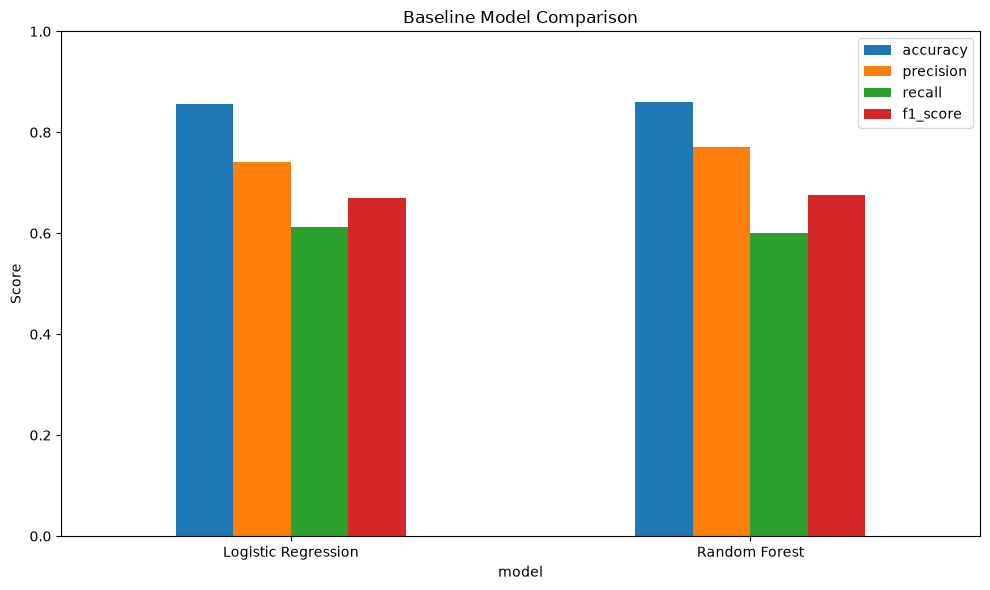

In [6]:
baseline_df.set_index("model")[
    ["accuracy", "precision", "recall", "f1_score"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "baseline_model_comparison.png",
    dpi=150
)
plt.show()